In [1]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Lambda,Dropout
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping
import shap
import warnings
import logging
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler     
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from sklearn.utils import check_array
from tensorflow.keras.losses import mean_squared_error
import seaborn as sns
from sklearn.utils.validation import check_is_fitted
from tensorflow.keras.models import Sequential
from tensorflow.keras.regularizers import l2
from mpl_toolkits.mplot3d import Axes3D
import tensorflow as tf
import math
from sklearn.metrics import roc_auc_score
from scipy.optimize import curve_fit
from itertools import combinations
from keras.models import load_model

from ODBAE import ODBAE

In [2]:
warnings.filterwarnings("ignore")
logger = logging.getLogger('shap')
logger.disabled = True

hidden_activation='relu'
output_activation='sigmoid'
loss=mean_squared_error
optimizer='adam'
epochs=60
batch_size=64
dropout_rate=0.2
l2_regularizer=10e-7
verbose=1
contamination=0.1

Loading dataset

In [3]:
X_test_raw=pd.read_csv('Data/IMPC_development_experiment.csv')
X_train_raw=pd.read_csv('Data/IMPC_development_control.csv')
X_test_raw=X_test_raw.drop(X_test_raw.index[[7685]])
X_test_raw=X_test_raw.reset_index(drop=True)

X_test_raw_center=pd.DataFrame()
X_train_raw_center=pd.DataFrame()
for i in range(X_test_raw.shape[1]):
    X_test_raw_center[X_test_raw.columns[i]]=X_test_raw[X_test_raw.columns[i]]
for i in range(X_train_raw.shape[1]):
    X_train_raw_center[X_train_raw.columns[i]]=X_train_raw[X_train_raw.columns[i]]
    
X_test_raw_center['phenotyping_center_use']=X_test_raw['phenotyping_center']
X_train_raw_center['phenotyping_center_use']=X_train_raw['phenotyping_center']
X_test_raw_center['raw_index']=list(X_test_raw.index)
X_train_raw_center['raw_index']=list(X_train_raw.index)

center_list=X_test_raw_center.phenotyping_center.unique().tolist()
X_train_raw_center=X_train_raw_center.set_index('phenotyping_center')
X_test_raw_center=X_test_raw_center.set_index('phenotyping_center')

In [4]:
X_test_raw_for_compute=pd.DataFrame()
X_train_raw_for_compute=pd.DataFrame()
for i in range(X_test_raw.shape[1]):
    X_test_raw_for_compute[X_test_raw.columns[i]]=X_test_raw[X_test_raw.columns[i]]
for i in range(X_train_raw.shape[1]):
    X_train_raw_for_compute[X_train_raw.columns[i]]=X_train_raw[X_train_raw.columns[i]]
X_test_raw_for_compute_sex=X_test_raw_for_compute.set_index('sex')
X_train_raw_for_compute_sex=X_train_raw_for_compute.set_index('sex')
X_test_raw_for_compute_male=X_test_raw_for_compute_sex.loc['male']
X_test_raw_for_compute_female=X_test_raw_for_compute_sex.loc['female']
X_train_raw_for_compute_male=X_train_raw_for_compute_sex.loc['male']
X_train_raw_for_compute_female=X_train_raw_for_compute_sex.loc['female']
X_test_raw_for_compute_male['phenotyping_center_use']=X_test_raw_for_compute_male['phenotyping_center']
X_test_raw_for_compute_female['phenotyping_center_use']=X_test_raw_for_compute_female['phenotyping_center']
X_train_raw_for_compute_male['phenotyping_center_use']=X_train_raw_for_compute_male['phenotyping_center']
X_train_raw_for_compute_female['phenotyping_center_use']=X_train_raw_for_compute_female['phenotyping_center']

X_test_raw_for_compute_male=X_test_raw_for_compute_male.reset_index(drop=True)
X_test_raw_for_compute_male=X_test_raw_for_compute_male.iloc[:,7:]
X_test_raw_for_compute_female=X_test_raw_for_compute_female.reset_index(drop=True)
X_test_raw_for_compute_female=X_test_raw_for_compute_female.iloc[:,7:]
X_train_raw_for_compute_male=X_train_raw_for_compute_male.reset_index(drop=True)
X_train_raw_for_compute_male=X_train_raw_for_compute_male.iloc[:,4:]
X_train_raw_for_compute_female=X_train_raw_for_compute_female.reset_index(drop=True)
X_train_raw_for_compute_female=X_train_raw_for_compute_female.iloc[:,4:]

In [5]:
X_train_with_center=pd.DataFrame()
X_test_with_center=pd.DataFrame()
X_train_with_center_tmp=pd.DataFrame()
X_test_with_center_tmp=pd.DataFrame()
normalize=MinMaxScaler()
normalize2=StandardScaler()

for i in range(len(center_list)):
    center=center_list[i]
    X_train_center=X_train_raw_center.loc[center]
    X_test_center=X_test_raw_center.loc[center]
    X_train_center=X_train_center.reset_index(drop=True)
    X_test_center=X_test_center.reset_index(drop=True)

    X_train_tmp=pd.DataFrame()
    X_train_tmp=X_train_tmp.append(X_train_center.iloc[:,4:X_train_center.shape[1]-2])

    X_test_tmp=pd.DataFrame()
    X_test_tmp=X_test_tmp.append(X_test_center.iloc[:,7:X_test_center.shape[1]-2])
    
    # Normalization
    X_train_normalize_tmp=pd.DataFrame(normalize2.fit_transform(X_train_tmp),columns=X_train_tmp.columns)
    X_test_normalize_tmp=pd.DataFrame(normalize2.transform(X_test_tmp),columns=X_test_tmp.columns)
    
    X_train_normalize_tmp['phenotyping_center']=X_train_center['phenotyping_center_use']
    X_train_normalize_tmp['sex']=X_train_center['sex']
    X_train_normalize_tmp['raw_index']=X_train_center['raw_index']
    X_test_normalize_tmp['phenotyping_center']=X_test_center['phenotyping_center_use']
    X_test_normalize_tmp['gene_symbol']=X_test_center['gene_symbol']
    X_test_normalize_tmp['sex']=X_test_center['sex']
    X_test_normalize_tmp['raw_index']=X_test_center['raw_index']
    X_train_with_center_tmp=X_train_with_center_tmp.append(X_train_normalize_tmp)
    X_test_with_center_tmp=X_test_with_center_tmp.append(X_test_normalize_tmp)

X_train_with_center_tmp=X_train_with_center_tmp.reset_index(drop=True)
X_test_with_center_tmp=X_test_with_center_tmp.reset_index(drop=True)
X_train_with_center_tmp1=pd.DataFrame()
X_train_with_center_tmp1=X_train_with_center_tmp1.append(X_train_with_center_tmp.iloc[:,0:X_train_with_center_tmp.shape[1]-3])
X_test_with_center_tmp1=pd.DataFrame()
X_test_with_center_tmp1=X_test_with_center_tmp1.append(X_test_with_center_tmp.iloc[:,0:X_test_with_center_tmp.shape[1]-4])

X_train_with_center=pd.DataFrame(normalize.fit_transform(X_train_with_center_tmp1),columns=X_train_tmp.columns)
X_test_with_center=pd.DataFrame(normalize.transform(X_test_with_center_tmp1),columns=X_test_tmp.columns)
X_train_with_center['phenotyping_center']=X_train_with_center_tmp['phenotyping_center']
X_train_with_center['sex']=X_train_with_center_tmp['sex']
X_train_with_center['raw_index']=X_train_with_center_tmp['raw_index']
X_test_with_center['phenotyping_center']=X_test_with_center_tmp['phenotyping_center']
X_test_with_center['gene_symbol']=X_test_with_center_tmp['gene_symbol']
X_test_with_center['sex']=X_test_with_center_tmp['sex']
X_test_with_center['raw_index']=X_test_with_center_tmp['raw_index']

X_train_without_center=pd.DataFrame()
X_train_without_center=X_train_without_center.append(X_train_with_center.iloc[:,0:X_train_with_center.shape[1]-3])
X_test_without_center=pd.DataFrame()
X_test_without_center=X_test_without_center.append(X_test_with_center.iloc[:,0:X_test_with_center.shape[1]-4])

Dividing dataset

In [6]:
# male
sex_filter1='male'

X_train_sex=X_train_with_center.set_index('sex')
X_test_sex=X_test_with_center.set_index('sex')
X_train_sex_filter_male_tmp=X_train_sex.loc[sex_filter1]
X_test_sex_filter_male_tmp=X_test_sex.loc[sex_filter1]
X_train_sex_filter_male_tmp=X_train_sex_filter_male_tmp.reset_index(drop=True)
X_test_sex_filter_male_tmp=X_test_sex_filter_male_tmp.reset_index(drop=True)
X_train_sex_filter_male=pd.DataFrame()
X_train_sex_filter_male=X_train_sex_filter_male.append(X_train_sex_filter_male_tmp.iloc[:,0:X_train_sex_filter_male_tmp.shape[1]-2])
X_test_sex_filter_male=pd.DataFrame()
X_test_sex_filter_male=X_test_sex_filter_male.append(X_test_sex_filter_male_tmp.iloc[:,0:X_test_sex_filter_male_tmp.shape[1]-3])
X_test_sex_filter_male_gene=pd.DataFrame()
X_test_sex_filter_male_gene=X_test_sex_filter_male_gene.append(X_test_sex_filter_male_tmp.iloc[:,0:X_test_sex_filter_male_tmp.shape[1]])

X_train_sex_original=X_train_with_center_tmp.set_index('sex')
X_test_sex_original=X_test_with_center_tmp.set_index('sex')
X_train_sex_filter_male_tmp_original=X_train_sex_original.loc[sex_filter1]
X_test_sex_filter_male_tmp_original=X_test_sex_original.loc[sex_filter1]
X_train_sex_filter_male_tmp_original=X_train_sex_filter_male_tmp_original.reset_index(drop=True)
X_test_sex_filter_male_tmp_original=X_test_sex_filter_male_tmp_original.reset_index(drop=True)
X_train_sex_filter_male_original=pd.DataFrame()
X_train_sex_filter_male_original=X_train_sex_filter_male_original.append(X_train_sex_filter_male_tmp_original.iloc[:,0:X_train_sex_filter_male_tmp_original.shape[1]-2])
X_test_sex_filter_male_original=pd.DataFrame()
X_test_sex_filter_male_original=X_test_sex_filter_male_original.append(X_test_sex_filter_male_tmp_original.iloc[:,0:X_test_sex_filter_male_tmp_original.shape[1]-3])
X_test_sex_filter_male_gene_original=pd.DataFrame()
X_test_sex_filter_male_gene_original=X_test_sex_filter_male_gene_original.append(X_test_sex_filter_male_tmp_original.iloc[:,0:X_test_sex_filter_male_tmp_original.shape[1]])

# female
sex_filter2='female'

X_train_sex_filter_female_tmp=X_train_sex.loc[sex_filter2]
X_test_sex_filter_female_tmp=X_test_sex.loc[sex_filter2]
X_train_sex_filter_female_tmp=X_train_sex_filter_female_tmp.reset_index(drop=True)
X_test_sex_filter_female_tmp=X_test_sex_filter_female_tmp.reset_index(drop=True)
X_train_sex_filter_female=pd.DataFrame()
X_train_sex_filter_female=X_train_sex_filter_female.append(X_train_sex_filter_female_tmp.iloc[:,0:X_train_sex_filter_female_tmp.shape[1]-2])
X_test_sex_filter_female=pd.DataFrame()
X_test_sex_filter_female=X_test_sex_filter_female.append(X_test_sex_filter_female_tmp.iloc[:,0:X_test_sex_filter_female_tmp.shape[1]-3])
X_test_sex_filter_female_gene=pd.DataFrame()
X_test_sex_filter_female_gene=X_test_sex_filter_female_gene.append(X_test_sex_filter_female_tmp.iloc[:,0:X_test_sex_filter_female_tmp.shape[1]])

X_train_sex_filter_female_tmp_original=X_train_sex_original.loc[sex_filter2]
X_test_sex_filter_female_tmp_original=X_test_sex_original.loc[sex_filter2]
X_train_sex_filter_female_tmp_original=X_train_sex_filter_female_tmp_original.reset_index(drop=True)
X_test_sex_filter_female_tmp_original=X_test_sex_filter_female_tmp_original.reset_index(drop=True)
X_train_sex_filter_female_original=pd.DataFrame()
X_train_sex_filter_female_original=X_train_sex_filter_female_original.append(X_train_sex_filter_female_tmp_original.iloc[:,0:X_train_sex_filter_female_tmp_original.shape[1]-2])
X_test_sex_filter_female_original=pd.DataFrame()
X_test_sex_filter_female_original=X_test_sex_filter_female_original.append(X_test_sex_filter_female_tmp_original.iloc[:,0:X_test_sex_filter_female_tmp_original.shape[1]-3])
X_test_sex_filter_female_gene_original=pd.DataFrame()
X_test_sex_filter_female_gene_original=X_test_sex_filter_female_gene_original.append(X_test_sex_filter_female_tmp_original.iloc[:,0:X_test_sex_filter_female_tmp_original.shape[1]])

In [7]:
X_test_raw = X_test_sex_filter_female_gene.iloc[:,0:8]
X_test_raw['gene_symbol'] = X_test_sex_filter_female_gene['gene_symbol']

X_train_raw = X_train_sex_filter_female
train_category = []
for i in range(X_train_raw.shape[0]):
    train_category.append('None')
X_train_raw['gene_symbol'] = train_category
X_train_raw = X_train_raw.reset_index(drop=True)
X_test_raw = X_test_raw.reset_index(drop=True)

Revised loss function

In [8]:
def def_loss(y_actual,y_pred):
    data_real_dim=7  # intrinsic dimension
    
    y_actual_tensor=tf.subtract(y_actual,0,name=None)
    y_actual_tensor=tf.cast(y_actual_tensor, tf.float64)
    y_pred_tensor=tf.subtract(y_pred,0,name=None)
    y_pred_tensor=tf.cast(y_pred_tensor, tf.float64)
    mean_actual_tensor = tf.reduce_mean(y_actual_tensor, axis=0, keepdims=True)
    mean_pred_tensor = tf.reduce_mean(y_pred_tensor, axis=0, keepdims=True)
    cov_actual= tf.matmul(tf.transpose(y_actual_tensor-mean_actual_tensor), y_actual_tensor-mean_actual_tensor)/tf.cast(tf.shape(y_actual_tensor)[0]-1, tf.float64)
    cov_pred= tf.matmul(tf.transpose(y_pred_tensor-mean_pred_tensor), y_pred_tensor-mean_pred_tensor)/tf.cast(tf.shape(y_pred_tensor)[0]-1, tf.float64)
    cov_inv_actual=tf.linalg.inv(cov_actual)
    mashi_loss=tf.reduce_sum(tf.matmul(y_actual_tensor-y_pred_tensor, cov_inv_actual)*(y_actual_tensor-y_pred_tensor))
    eigenvalues_actual, eigenvectors_actual=tf.linalg.eigh(cov_actual)
    eigenvalues_pred, eigenvectors_pred=tf.linalg.eigh(cov_pred)
    eigenvalues_actual_sort_to_control=tf.sort(eigenvalues_actual,direction='DESCENDING')[0:data_real_dim]
    eigenvalues_pred_sort_to_control=tf.sort(eigenvalues_pred,direction='DESCENDING')[0:data_real_dim]
    sqrt_eigenvalues_actual_to_control=tf.sqrt(eigenvalues_actual_sort_to_control, name=None)
    sqrt_eigenvalues_pred_to_control=tf.sqrt(eigenvalues_pred_sort_to_control, name=None)
    
    eigenvalues_actual_sort=tf.sort(eigenvalues_actual,direction='DESCENDING')
    sqrt_eigenvalues_actual=tf.sqrt(eigenvalues_actual_sort, name=None)
    beta_control_list=0.3*sqrt_eigenvalues_actual
    beta_list=sqrt_eigenvalues_actual
    max_beta_control_list=tf.reduce_max(beta_control_list)
    max_beta_control_list_reshape=tf.reshape(max_beta_control_list,[1])
    min_beta_list=tf.reduce_min(beta_list)
    min_beta_list_reshape=tf.reshape(min_beta_list,[1])
    combine_beta_list=tf.concat([max_beta_control_list_reshape,min_beta_list_reshape], axis=0)
    beta_control_value=tf.reduce_min(combine_beta_list)

    eigenvalues_diff=tf.subtract(sqrt_eigenvalues_actual_to_control,sqrt_eigenvalues_pred_to_control,name=None)
    eigenvalues_diff_cast=tf.cast(eigenvalues_diff,tf.float64)
    eigenvalues_diff_control=tf.subtract(eigenvalues_diff_cast,beta_control_value,name=None)
    eigenvalues_diff_control_square=tf.reduce_mean(tf.square(eigenvalues_diff_control))
    
    mean_loss=tf.reduce_mean(tf.square(y_actual_tensor-y_pred_tensor))
    
    final_loss=0.008*mean_loss+eigenvalues_diff_control_square
    
    return final_loss

Loading trained model

In [9]:
autoencoder = load_model('Trained_models/developmental_analysis_female_trained_model',custom_objects={"def_loss":def_loss})

Outlier detection and analysis

In [10]:
outlier_detection_model = ODBAE(reconstruction_error_percent=0.5)  
category_based_anomaly_explanation, instance_based_anomaly_explanation = outlier_detection_model.outlier_analysis(x_train_raw=X_train_raw,  
                                                                 x_test_raw = X_test_raw, 
                                                                autoencoder = autoencoder,  
                                                                abnormal_rate = 1724/X_test_raw.shape[0], 
                                                                batch_parameter = None,
                                                                normalize = False,
                                                                category_parameter = 'gene_symbol')

1 118
2 118
3 118
4 118
5 118
6 118
7 118
8 118
9 118
10 118
11 118
12 118
13 118
14 118
15 118
16 118
17 118
18 118
19 118
20 118
21 118
22 118
23 118
24 118
25 118
26 118
27 118
28 118
29 118
30 118
31 118
32 118
33 118
34 118
35 118
36 118
37 118
38 118
39 118
40 118
41 118
42 118
43 118
44 118
45 118
46 118
47 118
48 118
49 118
50 118
51 118
52 118
53 118
54 118
55 118
56 118
57 118
58 118
59 118
60 118
61 118
62 118
63 118
64 118
65 118
66 118
67 118
68 118
69 118
70 118
71 118
72 118
73 118
74 118
75 118
76 118
77 118
78 118
79 118
80 118
81 118
82 118
83 118
84 118
85 118
86 118
87 118
88 118
89 118
90 118
91 118
92 118
93 118
94 118
95 118
96 118
97 118
98 118
99 118
100 118
101 118
102 118
103 118
104 118
105 118
106 118
107 118
108 118
109 118
110 118
111 118
112 118
113 118
114 118
115 118
116 118
117 118
118 118
1 1224
2 1224
3 1224
4 1224
5 1224
6 1224
7 1224
8 1224
9 1224
10 1224
11 1224
12 1224
13 1224
14 1224
15 1224
16 1224
17 1224
18 1224
19 1224
20 1224
21 1224
22 12

831 1224
832 1224
833 1224
834 1224
835 1224
836 1224
837 1224
838 1224
839 1224
840 1224
841 1224
842 1224
843 1224
844 1224
845 1224
846 1224
847 1224
848 1224
849 1224
850 1224
851 1224
852 1224
853 1224
854 1224
855 1224
856 1224
857 1224
858 1224
859 1224
860 1224
861 1224
862 1224
863 1224
864 1224
865 1224
866 1224
867 1224
868 1224
869 1224
870 1224
871 1224
872 1224
873 1224
874 1224
875 1224
876 1224
877 1224
878 1224
879 1224
880 1224
881 1224
882 1224
883 1224
884 1224
885 1224
886 1224
887 1224
888 1224
889 1224
890 1224
891 1224
892 1224
893 1224
894 1224
895 1224
896 1224
897 1224
898 1224
899 1224
900 1224
901 1224
902 1224
903 1224
904 1224
905 1224
906 1224
907 1224
908 1224
909 1224
910 1224
911 1224
912 1224
913 1224
914 1224
915 1224
916 1224
917 1224
918 1224
919 1224
920 1224
921 1224
922 1224
923 1224
924 1224
925 1224
926 1224
927 1224
928 1224
929 1224
930 1224
931 1224
932 1224
933 1224
934 1224
935 1224
936 1224
937 1224
938 1224
939 1224
940 1224
941 1224
9

Abnormal physiological indicators of the Ckb strain

In [11]:
category_based_anomaly_explanation_index = category_based_anomaly_explanation.set_index('category_col')
category_based_anomaly_explanation_index['explain_result']['Ckb']

category_col
Ckb    [Body length, Body weight]
Ckb    [Body length, Body weight]
Ckb    [Body length, Body weight]
Ckb    [Body length, Body weight]
Name: explain_result, dtype: object

Visualization

[None, None, None]

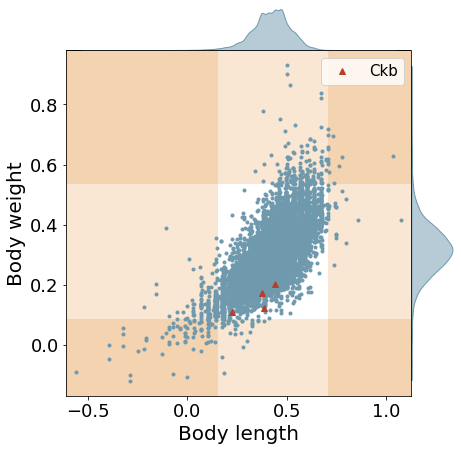

In [12]:
gene='Ckb'  
feature1 = 'Body length'
feature2 = 'Body weight'
P1=pd.DataFrame()
P1[feature1]=X_test_raw[feature1]
P1_mean=np.mean(P1[feature1])
P1['deviate']=P1[feature1]-P1_mean
P1['abs_deviate']=np.abs(P1[feature1]-P1_mean)
P1_sort=P1.sort_values(by=['abs_deviate'],ascending=False)
P1_sort_index_list=list(P1_sort.index)
P1_negative=[]
P1_positive=[]
for i in range(int(0.02*X_test_raw.shape[0])):
    if P1_sort['deviate'][P1_sort_index_list[i]]<0:
        P1_negative.append(P1_sort[feature1][P1_sort_index_list[i]])
    if P1_sort['deviate'][P1_sort_index_list[i]]>0:
        P1_positive.append(P1_sort[feature1][P1_sort_index_list[i]])
P1_neg_max=max(P1_negative)
P1_pos_min=min(P1_positive)

P2=pd.DataFrame()
P2[feature2]=X_test_raw[feature2]
P2_mean=np.mean(P2[feature2])
P2['deviate']=P2[feature2]-P2_mean
P2['abs_deviate']=np.abs(P2[feature2]-P2_mean)
P2_sort=P2.sort_values(by=['abs_deviate'],ascending=False)
P2_sort_index_list=list(P2_sort.index)
P2_negative=[]
P2_positive=[]
for i in range(int(0.02*X_test_raw.shape[0])):
    if P2_sort['deviate'][P2_sort_index_list[i]]<0:
        P2_negative.append(P2_sort[feature2][P2_sort_index_list[i]])
    if P2_sort['deviate'][P2_sort_index_list[i]]>0:
        P2_positive.append(P2_sort[feature2][P2_sort_index_list[i]])
P2_neg_max=max(P2_negative)
P2_pos_min=min(P2_positive)

category_based_anomaly_explanation_tmp = pd.DataFrame()
for i in range(category_based_anomaly_explanation.shape[1]):
    category_based_anomaly_explanation_tmp[category_based_anomaly_explanation.columns[i]]=category_based_anomaly_explanation[category_based_anomaly_explanation.columns[i]]
category_based_anomaly_explanation_tmp['index']=category_based_anomaly_explanation_tmp['original_index']
category_based_anomaly_explanation_tmp=category_based_anomaly_explanation_tmp.set_index('category_col')
ob_data_index=category_based_anomaly_explanation_tmp.loc[gene]
ob_data_index_list=ob_data_index.original_index.tolist()
ob_gene_data=pd.DataFrame()
gene_drop=pd.DataFrame()
for i in range(X_test_raw.shape[0]):
    if i in ob_data_index_list:
        ob_gene_data=ob_gene_data.append(X_test_raw[i:i+1])
    else:
        gene_drop=gene_drop.append(X_test_raw[i:i+1])

fig=plt.figure(figsize=(6,6))
ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.8])  
ax2 = fig.add_axes([0.1, 0.9, 0.8, 0.1])  
ax3 = fig.add_axes([0.9, 0.1, 0.1, 0.8])  
ax1.plot(gene_drop[feature1],gene_drop[feature2],'.',color='#6F99ADFF')
ax1.plot(ob_gene_data[feature1],ob_gene_data[feature2],'^',color='#BC3C29FF',label=gene)
sns.kdeplot(data=X_test_raw, x=feature1, shade=True, alpha=0.5, ax=ax2, legend=False,color='#6F99ADFF')
sns.kdeplot(data=X_test_raw, x=feature2, shade=True, alpha=0.5, vertical=True, ax=ax3, legend=False,color='#6F99ADFF')


xmin=min(X_test_raw[feature1])-0.05
xmax=max(X_test_raw[feature1])+0.05
ymin=min(X_test_raw[feature2])-0.05
ymax=max(X_test_raw[feature2])+0.05
ax1.axhspan(ymin, P2_neg_max, facecolor='#E18727FF', alpha=0.2)
ax1.axhspan(P2_pos_min, ymax, facecolor='#E18727FF', alpha=0.2)
ax1.axvspan(xmin, P1_neg_max, facecolor='#E18727FF', alpha=0.2)
ax1.axvspan(P1_pos_min, xmax, facecolor='#E18727FF', alpha=0.2)

ax1.set_xlim(xmin,xmax)
ax1.set_ylim(ymin,ymax)
ax1.tick_params(labelsize=18)
ax1.set_xlabel('Body length',fontsize=20)
ax1.set_ylabel('Body weight',fontsize=20)
ax1.legend(prop=dict(size=15),bbox_to_anchor=(0.74, 0.9),loc=3, borderaxespad=0)

ax2.set_ylim(bottom=-0.01)
ax2.set_xlabel(None)
ax2.set_ylabel(None)
ax2.set_xticks([])
ax2.set_yticks([])
[ax2.spines[x].set_visible(False) for x in ['right', 'top', 'left']]

ax3.set_xlim(left=-0.01)
ax3.set_xlabel(None)
ax3.set_ylabel(None)
ax3.set_xticks([])
ax3.set_yticks([])
[ax3.spines[x].set_visible(False) for x in ['right', 'top', 'bottom']]

In [25]:
# category_based_anomaly_explanation.to_csv('../Results/category_based_anomaly_explanation.csv',index=False)
# instance_based_anomaly_explanation.to_csv('../Results/instance_based_anomaly_explanation.csv',index=False)